# MLnode MNIST Training Notebook

This notebook demonstrates the full MLnode pipeline:
1. **Define** a CNN architecture as JSON
2. **Validate** tensor shapes statically
3. **Build** an executable `nn.Module`
4. **Train** on MNIST with a complete data pipeline
5. **Evaluate** accuracy on the test set

In [1]:
# Install MLnode (run once)
# !pip install -e /path/to/mlnode
# Or if already installed:
from mlnode import MLnodeModel
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import time

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
print(f"PyTorch: {torch.__version__}")

Device: cuda
PyTorch: 2.12.0+cu130


## 1. Define the Model as JSON

The corrected CNN architecture for MNIST:

```
Input (1, 28, 28)
  → Conv2d(1→32, k=3, p=1) → ReLU     → (32, 28, 28)
  → Conv2d(32→64, k=3, p=1) → ReLU    → (64, 28, 28)
  → MaxPool2d(2)                        → (64, 14, 14)
  → Dropout(0.25)
  → Flatten                             → (12544,)
  → Linear(12544→128) → ReLU
  → Dropout(0.5)
  → Linear(128→10)                      → (10,) logits
```

In [2]:
model_json = f"mnist_cnn.mlnode.json"

## 2. Validate Shapes Statically

In [3]:
# Parse and validate — no GPU memory allocated
model = MLnodeModel.load(model_json)
result = model.validate()

print(f"Valid: {result.valid}")
print(f"\nShape propagation through the graph:")
for node_id, shape in result.node_shapes.items():
    print(f"  {node_id:15s} → {shape}")

if not result.valid:
    print(f"\nErrors:")
    for err in result.errors:
        print(f"  {err.message}")

Valid: True

Shape propagation through the graph:
  input_0         → ('B', 1, 28, 28)
  conv1           → ('B', 32, 28, 28)
  relu1           → ('B', 32, 28, 28)
  conv2           → ('B', 64, 28, 28)
  relu2           → ('B', 64, 28, 28)
  pool            → ('B', 64, 14, 14)
  drop1           → ('B', 64, 14, 14)
  flatten         → ('B', 12544)
  fc1             → ('B', 128)
  relu3           → ('B', 128)
  drop2           → ('B', 128)
  linear_out      → ('B', 10)


## 3. Build the PyTorch Module

In [4]:
# Compile to nn.Module and move to device
module = model.build().to(device)

# Verify with a dummy input
dummy = torch.randn(1, 1, 28, 28, device=device)
out = module(dummy)
print(f"Input shape:  {dummy.shape}")
print(f"Output shape: {out.shape}")
print(f"Parameters:   {sum(p.numel() for p in module.parameters()):,}")
print(f"\nModule structure:")
print(module)

Input shape:  torch.Size([1, 1, 28, 28])
Output shape: torch.Size([1, 10])
Parameters:   1,625,866

Module structure:
MLnodeModule(
  (_layers): ModuleDict(
    (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (relu1): ReLU()
    (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (relu2): ReLU()
    (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (drop1): Dropout(p=0.25, inplace=False)
    (fc1): Linear(in_features=12544, out_features=128, bias=True)
    (relu3): ReLU()
    (drop2): Dropout(p=0.5, inplace=False)
    (linear_out): Linear(in_features=128, out_features=10, bias=True)
  )
)


## 4. Data Pipeline

MNIST: 60,000 training + 10,000 test images of handwritten digits (0-9), grayscale 28×28.

In [5]:
# Data transforms
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),  # MNIST mean and std
])

# Download and load datasets
train_dataset = datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)
test_dataset = datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

# Data loaders
BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True
)
test_loader = DataLoader(
    test_dataset, batch_size=1000, shuffle=False, num_workers=2, pin_memory=True
)

print(f"Training samples: {len(train_dataset):,}")
print(f"Test samples:     {len(test_dataset):,}")
print(f"Batch size:       {BATCH_SIZE}")
print(f"Training batches: {len(train_loader)}")

# Verify a batch
images, labels = next(iter(train_loader))
print(f"\nBatch shape:  {images.shape}")
print(f"Labels shape: {labels.shape}")
print(f"Label range:  {labels.min().item()} – {labels.max().item()}")

100%|██████████| 9.91M/9.91M [00:02<00:00, 4.29MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 199kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.41MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 19.1MB/s]

Training samples: 60,000
Test samples:     10,000
Batch size:       64
Training batches: 938



Batch shape:  torch.Size([64, 1, 28, 28])
Labels shape: torch.Size([64])
Label range:  0 – 9


## 5. Training Loop

In [6]:
# Hyperparameters
EPOCHS = 5
LEARNING_RATE = 1e-3

# Optimizer and loss
optimizer = optim.Adam(module.parameters(), lr=LEARNING_RATE)
criterion = nn.CrossEntropyLoss()

# Learning rate scheduler — reduce on plateau
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=2, factor=0.5)

print(f"Optimizer:     Adam (lr={LEARNING_RATE})")
print(f"Loss:          CrossEntropyLoss")
print(f"Epochs:        {EPOCHS}")
print(f"LR Scheduler:  ReduceLROnPlateau (patience=2, factor=0.5)")

Optimizer:     Adam (lr=0.001)
Loss:          CrossEntropyLoss
Epochs:        5
LR Scheduler:  ReduceLROnPlateau (patience=2, factor=0.5)


In [7]:
def train_epoch(module, loader, optimizer, criterion, device, epoch):
    module.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for batch_idx, (images, labels) in enumerate(loader):
        images, labels = images.to(device), labels.to(device)

        # Forward pass through the MLnode-built module
        outputs = module(images)
        loss = criterion(outputs, labels)

        # Backward pass
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Track metrics
        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

        if batch_idx % 200 == 0:
            print(f"  Epoch {epoch} [{batch_idx * len(images):>5d}/{len(loader.dataset)}]  "
                  f"Loss: {loss.item():.4f}  Acc: {100. * correct / total:.1f}%")

    epoch_loss = running_loss / total
    epoch_acc = 100. * correct / total
    return epoch_loss, epoch_acc


def evaluate(module, loader, criterion, device):
    module.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = module(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

    avg_loss = running_loss / total
    accuracy = 100. * correct / total
    return avg_loss, accuracy

In [8]:
# Training loop
history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}

print("=" * 60)
print(f"Training MNIST CNN ({sum(p.numel() for p in module.parameters()):,} params)")
print("=" * 60)

for epoch in range(1, EPOCHS + 1):
    start = time.time()

    train_loss, train_acc = train_epoch(module, train_loader, optimizer, criterion, device, epoch)
    test_loss, test_acc = evaluate(module, test_loader, criterion, device)

    scheduler.step(test_loss)
    elapsed = time.time() - start

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["test_loss"].append(test_loss)
    history["test_acc"].append(test_acc)

    print(f"\nEpoch {epoch}/{EPOCHS} ({elapsed:.1f}s)")
    print(f"  Train — Loss: {train_loss:.4f}  Acc: {train_acc:.2f}%")
    print(f"  Test  — Loss: {test_loss:.4f}  Acc: {test_acc:.2f}%")
    print(f"  LR:    {optimizer.param_groups[0]['lr']:.6f}")
    print()

print("=" * 60)
print(f"Final test accuracy: {history['test_acc'][-1]:.2f}%")
print("=" * 60)

Training MNIST CNN (1,625,866 params)
  Epoch 1 [    0/60000]  Loss: 2.3055  Acc: 10.9%
  Epoch 1 [12800/60000]  Loss: 0.3765  Acc: 85.5%
  Epoch 1 [25600/60000]  Loss: 0.1911  Acc: 90.3%
  Epoch 1 [38400/60000]  Loss: 0.1134  Acc: 92.1%
  Epoch 1 [51200/60000]  Loss: 0.2037  Acc: 93.2%

Epoch 1/5 (5.3s)
  Train — Loss: 0.2070  Acc: 93.70%
  Test  — Loss: 0.0448  Acc: 98.53%
  LR:    0.001000

  Epoch 2 [    0/60000]  Loss: 0.1618  Acc: 96.9%
  Epoch 2 [12800/60000]  Loss: 0.0795  Acc: 97.4%
  Epoch 2 [25600/60000]  Loss: 0.1136  Acc: 97.4%
  Epoch 2 [38400/60000]  Loss: 0.1171  Acc: 97.4%
  Epoch 2 [51200/60000]  Loss: 0.0474  Acc: 97.4%

Epoch 2/5 (4.8s)
  Train — Loss: 0.0843  Acc: 97.48%
  Test  — Loss: 0.0370  Acc: 98.74%
  LR:    0.001000

  Epoch 3 [    0/60000]  Loss: 0.1532  Acc: 93.8%
  Epoch 3 [12800/60000]  Loss: 0.0926  Acc: 98.0%
  Epoch 3 [25600/60000]  Loss: 0.0174  Acc: 98.0%
  Epoch 3 [38400/60000]  Loss: 0.2093  Acc: 98.1%
  Epoch 3 [51200/60000]  Loss: 0.0326  Acc: 

## 6. Training Curves

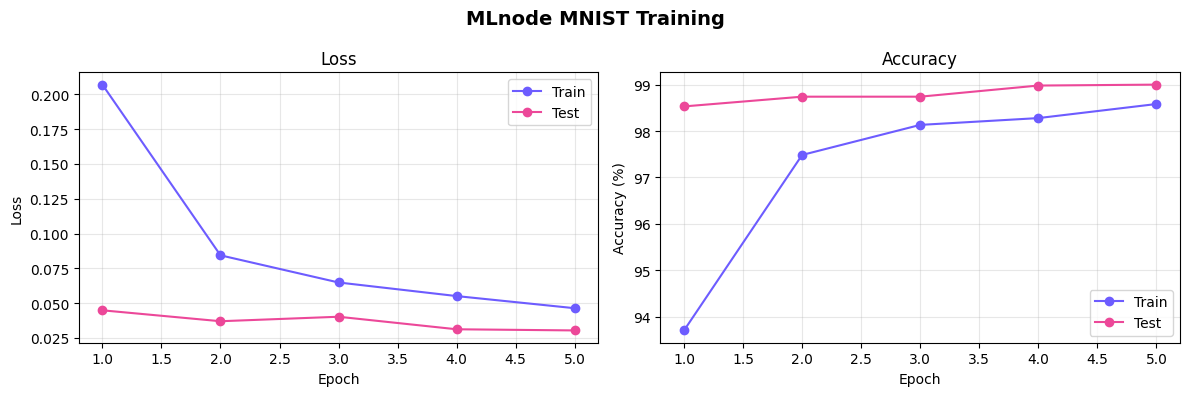

In [9]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

epochs_range = range(1, len(history["train_loss"]) + 1)

# Loss
ax1.plot(epochs_range, history["train_loss"], "o-", label="Train", color="#6d5cff")
ax1.plot(epochs_range, history["test_loss"], "o-", label="Test", color="#ec4899")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.set_title("Loss")
ax1.legend()
ax1.grid(alpha=0.3)

# Accuracy
ax2.plot(epochs_range, history["train_acc"], "o-", label="Train", color="#6d5cff")
ax2.plot(epochs_range, history["test_acc"], "o-", label="Test", color="#ec4899")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")
ax2.set_title("Accuracy")
ax2.legend()
ax2.grid(alpha=0.3)

plt.suptitle("MLnode MNIST Training", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## 7. Sample Predictions

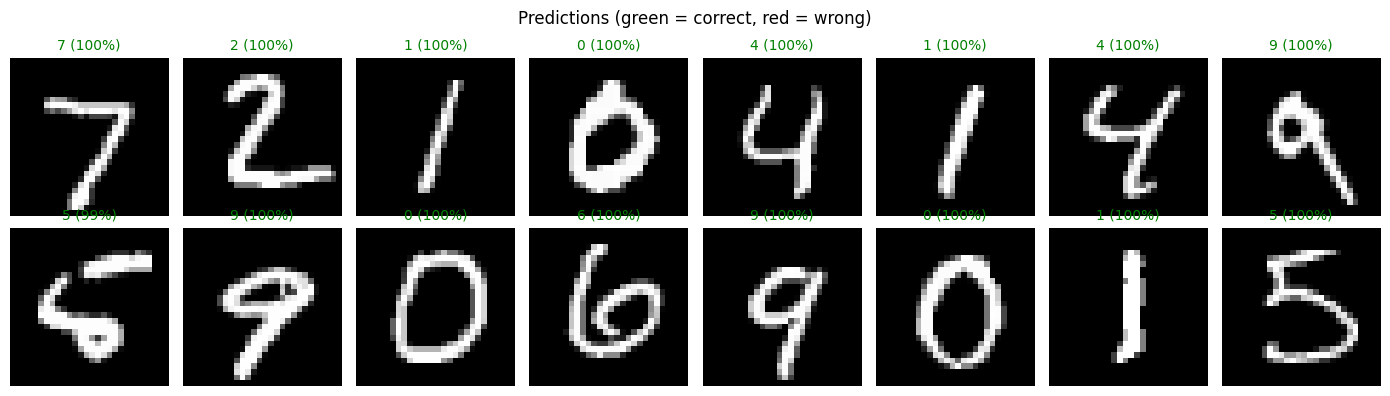

Batch accuracy: 988/1000 (98.8%)


In [10]:
# Visualize predictions on test samples
module.eval()
images, labels = next(iter(test_loader))
images, labels = images.to(device), labels.to(device)

with torch.no_grad():
    outputs = module(images)
    probs = torch.softmax(outputs, dim=1)
    preds = outputs.argmax(dim=1)

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    img = images[i].cpu().squeeze()
    pred = preds[i].item()
    true = labels[i].item()
    conf = probs[i][pred].item() * 100

    ax.imshow(img, cmap="gray")
    color = "green" if pred == true else "red"
    ax.set_title(f"{pred} ({conf:.0f}%)", color=color, fontsize=10)
    ax.axis("off")

plt.suptitle("Predictions (green = correct, red = wrong)", fontsize=12)
plt.tight_layout()
plt.show()

# Overall stats
correct = preds.eq(labels).sum().item()
total = len(labels)
print(f"Batch accuracy: {correct}/{total} ({100*correct/total:.1f}%)")

## 8. Save the Model

In [11]:
# Save the MLnode architecture JSON
model.save("mnist_cnn.mlnode.json")
print("Architecture saved to mnist_cnn.mlnode.json")

# Save trained PyTorch weights
torch.save(module.state_dict(), "mnist_cnn_weights.pth")
print("Weights saved to mnist_cnn_weights.pth")

# To reload later:
# model = MLnodeModel.load("mnist_cnn.mlnode.json")
# module = model.build()
# module.load_state_dict(torch.load("mnist_cnn_weights.pth"))

Architecture saved to mnist_cnn.mlnode.json
Weights saved to mnist_cnn_weights.pth
